# Two-Tower Recommender System on MovieLens

## Project Goal

This project studies the relationship between training loss, generalization, and Top-K retrieval performance in a Two-Tower recommender system.

We use the MovieLens Latest Small dataset and formulate recommendation as an implicit-feedback retrieval task.

The main machine learning components are:

- Hypothesis space \(H\): a family of Two-Tower neural recommender models
- Loss function \(L\): Binary Cross-Entropy (BCE)
- Learning algorithm: Adam-based gradient optimization
- $E_{in}$: empirical BCE loss on the training dataset
- $E_{out}$: BCE loss estimated on held-out validation/test data
- Practical task metrics: Recall@K and NDCG@K

The first MVP uses only user IDs and movie IDs as model inputs.

## 1. Environment Setup

We import the required Python libraries and set random seeds for reproducibility.

In [ ]:
import os
import random
import zipfile
import urllib.request

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

Using device: cuda


## Download MovieLens Latest Small and Inspect

The MovieLens Latest Small dataset contains real user-movie interactions.

The main files used in this project are:

- `ratings.csv`: userId, movieId, rating, timestamp
- `movies.csv`: movieId, title, genres

For the MVP, we primarily use `ratings.csv`.

In [ ]:
DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

ZIP_PATH = "/content/ml-latest-small.zip"
EXTRACT_DIR = "/content"

if not os.path.exists(ZIP_PATH):
    print("Downloading MovieLens dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

if not os.path.exists("/content/ml-latest-small"):
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

print("Dataset ready.")

Dataset ready.


**Load and Inspect the Dataset**

Each row in `ratings.csv` represents a user-movie interaction.

The raw rating scale is from 0.5 to 5.0.

For this project, we convert explicit ratings into implicit positive feedback.
A rating of 4.0 or above is treated as a positive interaction.

In [ ]:
ratings_path = "/content/ml-latest-small/ratings.csv"
movies_path = "/content/ml-latest-small/movies.csv"

ratings = pd.read_csv(ratings_path)
movies = pd.read_csv(movies_path)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

display(ratings.head())
display(movies.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
print("Number of unique users:", ratings["userId"].nunique())
print("Number of unique movies:", ratings["movieId"].nunique())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

Number of unique users: 610
Number of unique movies: 9724

Rating distribution:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


## 4. Convert Ratings into Implicit Positive Feedback

We define a positive interaction as:


$$
y_{ui} = 1 \quad \text{if rating} \geq 4.0
$$


Ratings below 4.0 are not directly used as negatives.

This is important because a low rating and an unseen item have different meanings.
For the MVP, negative examples will be sampled from movies that the user has never rated.

In [ ]:
positive_ratings = ratings[ratings["rating"] >= 4.0].copy()

print("Positive interactions:", len(positive_ratings))
print("Unique users with positives:", positive_ratings["userId"].nunique())
print("Unique movies with positives:", positive_ratings["movieId"].nunique())

display(positive_ratings.head())

Positive interactions: 48580
Unique users with positives: 609
Unique movies with positives: 6298


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 5. Encode User IDs and Movie IDs

PyTorch embedding layers require integer indices from 0 to \(N-1\).

Therefore, the original MovieLens user IDs and movie IDs are mapped into consecutive internal indices.

The original IDs are only identifiers and do not contain ordinal meaning.

In [ ]:
user_ids = sorted(positive_ratings["userId"].unique())
movie_ids = sorted(ratings["movieId"].unique())

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
movie_to_idx = {movie_id: idx for idx, movie_id in enumerate(movie_ids)}

idx_to_user = {idx: user_id for user_id, idx in user_to_idx.items()}
idx_to_movie = {idx: movie_id for movie_id, idx in movie_to_idx.items()}

positive_ratings["user_idx"] = positive_ratings["userId"].map(user_to_idx)
positive_ratings["movie_idx"] = positive_ratings["movieId"].map(movie_to_idx)

NUM_USERS = len(user_to_idx)
NUM_MOVIES = len(movie_to_idx)

print("NUM_USERS =", NUM_USERS)
print("NUM_MOVIES =", NUM_MOVIES)

NUM_USERS = 609
NUM_MOVIES = 9724


## 6. Chronological Train / Validation / Test Split

Recommendation is naturally a temporal prediction problem.

For each user:

- the latest positive interaction is assigned to the test set;
- the second latest positive interaction is assigned to the validation set;
- all earlier positive interactions are assigned to the training set.

This reduces temporal leakage and better reflects deployment conditions.

In [ ]:
positive_ratings = positive_ratings.sort_values(["user_idx", "timestamp"])

train_rows = []
val_rows = []
test_rows = []

for user_idx, group in positive_ratings.groupby("user_idx"):
    group = group.sort_values("timestamp")

    # Skip users with too few positive interactions
    if len(group) < 3:
        continue

    train_rows.append(group.iloc[:-2])
    val_rows.append(group.iloc[-2:-1])
    test_rows.append(group.iloc[-1:])

train_pos = pd.concat(train_rows).reset_index(drop=True)
val_pos = pd.concat(val_rows).reset_index(drop=True)
test_pos = pd.concat(test_rows).reset_index(drop=True)

print("Train positives:", len(train_pos))
print("Validation positives:", len(val_pos))
print("Test positives:", len(test_pos))

Train positives: 47363
Validation positives: 608
Test positives: 608


## 7. Construct User Interaction History

Negative samples are drawn from movies that a user has never rated.

For each user, we therefore store the set of all movies previously rated by that user.

This avoids incorrectly sampling an already-observed movie as an unseen negative.

In [ ]:
ratings_encoded = ratings.copy()

ratings_encoded = ratings_encoded[
    ratings_encoded["userId"].isin(user_to_idx.keys())
].copy()

ratings_encoded["user_idx"] = ratings_encoded["userId"].map(user_to_idx)
ratings_encoded["movie_idx"] = ratings_encoded["movieId"].map(movie_to_idx)

user_seen_movies = (
    ratings_encoded
    .groupby("user_idx")["movie_idx"]
    .apply(set)
    .to_dict()
)

all_movie_indices = np.arange(NUM_MOVIES)

print("Example user seen movies:")
example_user = list(user_seen_movies.keys())[0]
print(example_user, list(user_seen_movies[example_user])[:10])

Example user seen movies:
0 [0, 513, 2, 5, 1542, 520, 2568, 2569, 1035, 2570]


## 8. Negative Sampling

MovieLens mainly provides observed interactions.

For implicit recommendation training, negative examples are sampled from movies that the user has never rated.

For the MVP, each positive training interaction is paired with four sampled negatives:

\[
1:4
\]

positive-to-negative ratio.

This ratio will initially remain fixed so that the effect of training loss and generalization can be studied without introducing too many experimental variables.

In [ ]:
NEGATIVES_PER_POSITIVE = 4

def sample_negative_movies(user_idx, num_negatives=4):
    seen = user_seen_movies[user_idx]

    candidates = [
        movie_idx
        for movie_idx in all_movie_indices
        if movie_idx not in seen
    ]

    sampled = np.random.choice(
        candidates,
        size=num_negatives,
        replace=False
    )

    return sampled

## 9. Construct the Training Dataset

Each training example has:

\[
(user, movie, y)
\]

where:

- \(y=1\) for an observed positive interaction;
- \(y=0\) for a sampled negative interaction.

The model will learn a score for each user-movie pair.

In [ ]:
train_examples = []

for row in tqdm(train_pos.itertuples(), total=len(train_pos)):
    user_idx = row.user_idx
    movie_idx = row.movie_idx

    # Positive example
    train_examples.append((user_idx, movie_idx, 1.0))

    # Negative examples
    negatives = sample_negative_movies(
        user_idx,
        NEGATIVES_PER_POSITIVE
    )

    for neg_movie_idx in negatives:
        train_examples.append(
            (user_idx, neg_movie_idx, 0.0)
        )

train_df = pd.DataFrame(
    train_examples,
    columns=["user_idx", "movie_idx", "label"]
)

print("Training examples:", len(train_df))
print(train_df["label"].value_counts())

display(train_df.head())

  0%|          | 0/47363 [00:00<?, ?it/s]

Training examples: 236815
label
0.0    189452
1.0     47363
Name: count, dtype: int64


,user_idx,movie_idx,label
0,0,632,1.0
1,0,1057,0.0
2,0,4830,0.0
3,0,5241,0.0
4,0,6812,0.0


Define the PyTorch Dataset

In [ ]:
class RecommendationDataset(Dataset):
    def __init__(self, dataframe):
        self.users = torch.tensor(
            dataframe["user_idx"].values,
            dtype=torch.long
        )

        self.movies = torch.tensor(
            dataframe["movie_idx"].values,
            dtype=torch.long
        )

        self.labels = torch.tensor(
            dataframe["label"].values,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.users[idx],
            self.movies[idx],
            self.labels[idx]
        )

In [ ]:
train_dataset = RecommendationDataset(train_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

print("Number of training batches:", len(train_loader))

Number of training batches: 463


## 10. Two-Tower Model

The hypothesis family \(H\) consists of Two-Tower neural models.

The user tower and movie tower independently map IDs into learned 32-dimensional representations.

For a user \(u\) and movie \(i\):


$$z_u = f_{\theta_u}(u)$$

$$z_i = g_{\theta_i}(i)$$


The interaction score is:

$$
s(u,i) = z_u^T z_i
$$

A sigmoid transformation converts the score into a value between 0 and 1:

$$
\hat{y}_{ui} = \sigma(s(u,i))
$$


In [ ]:
class TwoTowerModel(nn.Module):
    def __init__(
        self,
        num_users,
        num_movies,
        embedding_dim=32,
        hidden_dim=64
    ):
        super().__init__()

        # Learnable ID embeddings
        self.user_embedding = nn.Embedding(
            num_users,
            embedding_dim
        )

        self.movie_embedding = nn.Embedding(
            num_movies,
            embedding_dim
        )

        # User tower
        self.user_tower = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

        # Movie tower
        self.movie_tower = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

    def forward(self, user_idx, movie_idx):
        user_emb = self.user_embedding(user_idx)
        movie_emb = self.movie_embedding(movie_idx)

        user_vec = self.user_tower(user_emb)
        movie_vec = self.movie_tower(movie_emb)

        # Dot product similarity
        score = torch.sum(
            user_vec * movie_vec,
            dim=1
        )

        return score

    def encode_users(self, user_idx):
        user_emb = self.user_embedding(user_idx)
        return self.user_tower(user_emb)

    def encode_movies(self, movie_idx):
        movie_emb = self.movie_embedding(movie_idx)
        return self.movie_tower(movie_emb)

## 11. Loss Function and Learning Algorithm

The training criterion is Binary Cross-Entropy.

Because the model directly outputs logits, PyTorch's `BCEWithLogitsLoss` is used.


The empirical training risk is:

$$
E_{in}(h) =
\frac{1}{N}
\sum_{i=1}^{N}
L(h(x_i), y_i)
$$


Adam is used as the learning algorithm's optimizer to iteratively update model parameters.

In [ ]:
model = TwoTowerModel(
    num_users=NUM_USERS,
    num_movies=NUM_MOVIES,
    embedding_dim=32,
    hidden_dim=64
).to(DEVICE)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(model)

TwoTowerModel(
  (user_embedding): Embedding(609, 32)
  (movie_embedding): Embedding(9724, 32)
  (user_tower): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
  )
  (movie_tower): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
  )
)


## Training Function

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    total_examples = 0

    for users, movies, labels in loader:
        users = users.to(DEVICE)
        movies = movies.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        logits = model(users, movies)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_examples += batch_size

    average_loss = total_loss / total_examples

    return average_loss

## 12. Top-K Retrieval Evaluation

During deployment, the system does not classify only one user-movie pair.

Instead, for each user, the model scores a large candidate set and retrieves the Top-K movies.

For the MVP, retrieval quality is evaluated using:

- Recall@K
- NDCG@K

Since each validation/test user has one held-out positive movie, Recall@K is 1 if the held-out movie appears in the Top-K list and 0 otherwise.

In [ ]:
def evaluate_retrieval(
    model,
    target_df,
    train_positive_df,
    k=20
):
    model.eval()

    # Movies seen in positive training data
    train_seen = (
        train_positive_df
        .groupby("user_idx")["movie_idx"]
        .apply(set)
        .to_dict()
    )

    all_movies_tensor = torch.arange(
        NUM_MOVIES,
        device=DEVICE
    )

    with torch.no_grad():
        all_movie_vectors = model.encode_movies(
            all_movies_tensor
        )

    recalls = []
    ndcgs = []

    for row in target_df.itertuples():
        user_idx = row.user_idx
        target_movie = row.movie_idx

        user_tensor = torch.tensor(
            [user_idx],
            dtype=torch.long,
            device=DEVICE
        )

        with torch.no_grad():
            user_vector = model.encode_users(user_tensor)

            scores = torch.matmul(
                all_movie_vectors,
                user_vector.squeeze(0)
            )

        # Exclude training positives
        seen_movies = train_seen.get(user_idx, set())

        scores = scores.clone()

        for movie_idx in seen_movies:
            scores[movie_idx] = -float("inf")

        topk = torch.topk(
            scores,
            k=k
        ).indices.cpu().numpy()

        if target_movie in topk:
            rank = np.where(topk == target_movie)[0][0] + 1

            recall = 1.0

            ndcg = 1.0 / np.log2(rank + 1)

        else:
            recall = 0.0
            ndcg = 0.0

        recalls.append(recall)
        ndcgs.append(ndcg)

    return {
        f"Recall@{k}": np.mean(recalls),
        f"NDCG@{k}": np.mean(ndcgs)
    }

def build_fixed_evaluation_dataset(
    positive_df,
    negatives_per_positive=4,
    seed=123
):
    rng = np.random.default_rng(seed)

    examples = []

    for row in positive_df.itertuples():
        user_idx = row.user_idx
        positive_movie = row.movie_idx

        # Positive example
        examples.append(
            (user_idx, positive_movie, 1.0)
        )

        # Movies this user has already rated
        seen = user_seen_movies[user_idx]

        candidates = np.array([
            movie_idx
            for movie_idx in all_movie_indices
            if movie_idx not in seen
        ])

        negatives = rng.choice(
            candidates,
            size=negatives_per_positive,
            replace=False
        )

        for neg_movie in negatives:
            examples.append(
                (user_idx, neg_movie, 0.0)
            )

    return pd.DataFrame(
        examples,
        columns=["user_idx", "movie_idx", "label"]
    )

In [ ]:
val_df = build_fixed_evaluation_dataset(
    val_pos,
    negatives_per_positive=NEGATIVES_PER_POSITIVE,
    seed=123
)

val_dataset = RecommendationDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False
)

print("Validation examples:", len(val_df))
print(val_df["label"].value_counts())

Validation examples: 3040
label
0.0    2432
1.0     608
Name: count, dtype: int64


In [ ]:
def evaluate_bce(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for users, movies, labels in loader:
            users = users.to(DEVICE)
            movies = movies.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(users, movies)

            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_examples += batch_size

    return total_loss / total_examples

## 13. MVP Training Experiment

The model is trained for 10 epochs.

For each epoch, we record:

- empirical training BCE loss;
- validation Recall@20;
- validation NDCG@20.

This allows us to observe whether a reduction in training loss corresponds to improved retrieval quality.

In [ ]:
import copy

NUM_EPOCHS = 10

history = []

best_recall = -1.0
best_epoch = -1
best_model_state = None

for epoch in range(1, NUM_EPOCHS + 1):

    # 1. Train for one epoch
    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )
    # Validation BCE
    # -------------------------
    val_loss = evaluate_bce(
        model,
        val_loader,
        criterion
    )
    # Evaluate retrieval performance on validation set
    val_metrics = evaluate_retrieval(
        model,
        val_pos,
        train_pos,
        k=20
    )

    recall_20 = val_metrics["Recall@20"]
    ndcg_20 = val_metrics["NDCG@20"]

    # 3. Save the best checkpoint according to Recall@20
    if recall_20 > best_recall:
        best_recall = recall_20
        best_epoch = epoch

        # Deep copy is important:
        # otherwise the stored weights would keep changing during later training
        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    # 4. Record metrics
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "Recall@20": recall_20,
        "NDCG@20": ndcg_20
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train BCE: {train_loss:.4f} | "
        f"Val BCE: {val_loss:.4f} | "
        f"Recall@20: {recall_20:.4f} | "
        f"NDCG@20: {ndcg_20:.4f}"
    )

print("\nTraining finished.")
print(
    f"Best Epoch: {best_epoch} | "
    f"Best Validation Recall@20: {best_recall:.4f}"
)

Epoch 01 | Train BCE: 0.4625 | Val BCE: 0.4230 | Recall@20: 0.0345 | NDCG@20: 0.0134
Epoch 02 | Train BCE: 0.3429 | Val BCE: 0.3665 | Recall@20: 0.0444 | NDCG@20: 0.0172
Epoch 03 | Train BCE: 0.3005 | Val BCE: 0.3572 | Recall@20: 0.0592 | NDCG@20: 0.0245
Epoch 04 | Train BCE: 0.2847 | Val BCE: 0.3444 | Recall@20: 0.0477 | NDCG@20: 0.0186
Epoch 05 | Train BCE: 0.2766 | Val BCE: 0.3457 | Recall@20: 0.0477 | NDCG@20: 0.0163
Epoch 06 | Train BCE: 0.2710 | Val BCE: 0.3520 | Recall@20: 0.0543 | NDCG@20: 0.0221
Epoch 07 | Train BCE: 0.2672 | Val BCE: 0.3479 | Recall@20: 0.0493 | NDCG@20: 0.0195
Epoch 08 | Train BCE: 0.2633 | Val BCE: 0.3519 | Recall@20: 0.0526 | NDCG@20: 0.0201
Epoch 09 | Train BCE: 0.2604 | Val BCE: 0.3662 | Recall@20: 0.0461 | NDCG@20: 0.0229
Epoch 10 | Train BCE: 0.2568 | Val BCE: 0.3639 | Recall@20: 0.0428 | NDCG@20: 0.0210

Training finished.
Best Epoch: 3 | Best Validation Recall@20: 0.0592


**Save the best Model**

The primary deployment objective of the Two-Tower model is candidate retrieval.

Therefore, validation Recall@20 is used as the primary model-selection metric.

During training, the checkpoint with the highest validation Recall@20 is retained.
The test set is not used for checkpoint selection.

In [ ]:
# Record the best Recall@20 model
model.load_state_dict(best_model_state)
model = model.to(DEVICE)

print(
    f"Loaded best model from Epoch {best_epoch} "
    f"with Validation Recall@20 = {best_recall:.4f}"
)

Loaded best model from Epoch 3 with Validation Recall@20 = 0.0592


## Plot Results
**Compare Training Risk and Validation Risk**

The training BCE approximates the empirical in-sample risk:

$$E_{in}
=
\frac{1}{N_{train}}
\sum_i L(h(x_i), y_i)$$


The validation BCE provides an empirical estimate of out-of-sample risk:

$$\hat{E}_{out}
=
\frac{1}{N_{val}}
\sum_i L(h(x_i), y_i)$$

Comparing these two curves helps identify whether continued reduction in training loss also improves generalization.

In [ ]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

display(history_df)

,epoch,train_loss,val_loss,Recall@20,NDCG@20
0,1,0.462547,0.423010,0.034539,0.013370
1,2,0.342941,0.366473,0.044408,0.017205
2,3,0.300536,0.357224,0.059211,0.024523
3,4,0.284734,0.344411,0.047697,0.018594
4,5,0.276620,0.345674,0.047697,0.016304
5,6,0.271011,0.352032,0.054276,0.022065
6,7,0.267191,0.347868,0.049342,0.019474
7,8,0.263324,0.351926,0.052632,0.020086
8,9,0.260396,0.366249,0.046053,0.022949
9,10,0.256813,0.363910,0.042763,0.021003


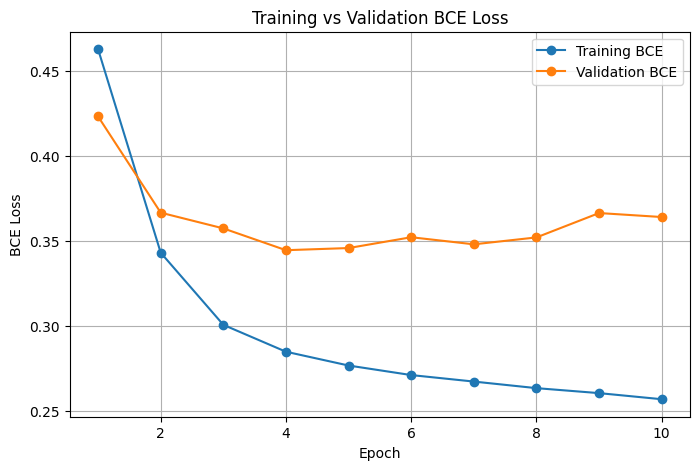

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training BCE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation BCE"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training vs Validation BCE Loss")
plt.legend()
plt.grid(True)

plt.show()

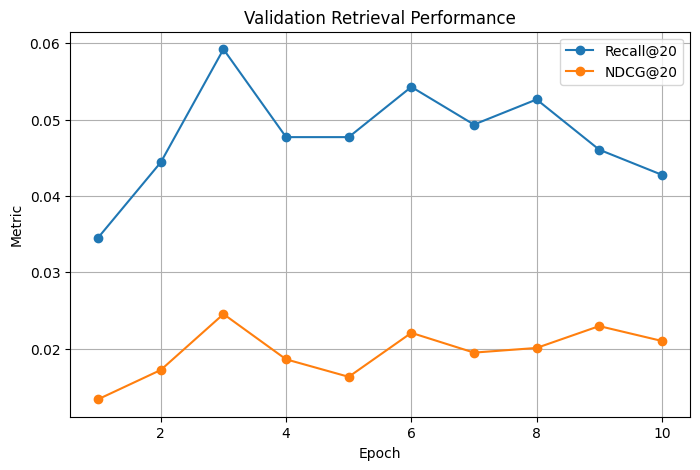

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["Recall@20"],
    marker="o",
    label="Recall@20"
)

plt.plot(
    history_df["epoch"],
    history_df["NDCG@20"],
    marker="o",
    label="NDCG@20"
)

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Validation Retrieval Performance")
plt.legend()
plt.grid(True)

plt.show()

## 14. Final Test Evaluation

After model development and validation, the final model is evaluated on the held-out test interactions.

The test set is not used during model development.

In [ ]:
test_metrics = evaluate_retrieval(
    model,
    test_pos,
    train_pos,
    k=20
)

print("Final Test Metrics:")
print(test_metrics)

Final Test Metrics:
{'Recall@20': np.float64(0.054276315789473686), 'NDCG@20': np.float64(0.02350606022866295)}


## Inspect Some Actual Recommendations

In [ ]:
movie_title_map = dict(
    zip(
        movies["movieId"],
        movies["title"]
    )
)

def recommend_movies(model, user_idx, k=10):
    model.eval()

    all_movies_tensor = torch.arange(
        NUM_MOVIES,
        device=DEVICE
    )

    user_tensor = torch.tensor(
        [user_idx],
        dtype=torch.long,
        device=DEVICE
    )

    with torch.no_grad():

        user_vector = model.encode_users(user_tensor)

        movie_vectors = model.encode_movies(
            all_movies_tensor
        )

        scores = torch.matmul(
            movie_vectors,
            user_vector.squeeze(0)
        )

    # Remove movies already rated by the user
    seen_movies = user_seen_movies[user_idx]

    scores = scores.clone()

    for movie_idx in seen_movies:
        scores[movie_idx] = -float("inf")

    topk_indices = torch.topk(
        scores,
        k=k
    ).indices.cpu().numpy()

    results = []

    for movie_idx in topk_indices:

        original_movie_id = idx_to_movie[movie_idx]

        title = movie_title_map.get(
            original_movie_id,
            "Unknown"
        )

        results.append(
            (
                original_movie_id,
                title
            )
        )

    return results

In [ ]:
example_user_idx = 0

recommendations = recommend_movies(
    model,
    example_user_idx,
    k=10
)

print(
    "Original user ID:",
    idx_to_user[example_user_idx]
)

for rank, (movie_id, title) in enumerate(
    recommendations,
    start=1
):
    print(rank, movie_id, title)

Original user ID: 1
1 318 Shawshank Redemption, The (1994)
2 1682 Truman Show, The (1998)
3 4993 Lord of the Rings: The Fellowship of the Ring, The (2001)
4 48516 Departed, The (2006)
5 5952 Lord of the Rings: The Two Towers, The (2002)
6 6539 Pirates of the Caribbean: The Curse of the Black Pearl (2003)
7 858 Godfather, The (1972)
8 589 Terminator 2: Judgment Day (1991)
9 4306 Shrek (2001)
10 4226 Memento (2000)
